In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the CSV
df = pd.read_csv("Player list csv.csv")

print("Dataset loaded successfully!")
print("Shape of dataset:", df.shape)

df.head()

Dataset loaded successfully!
Shape of dataset: (340, 20)


,Player_ID,Player_Name,Jersey_Number,Nationality,Player_Role,IPL_Franchise,Format,Age,Experience_Years,Matches_Played,Innings,Runs_Scored,Batting_Average,Strike_Rate,Wickets,Economy_Rate,Catches,Recent_Form_Score,Fitness_Score,Performance_Score
0,PLY0068,Abhinandan Singh,61,India,Bowler,Royal Challengers Bengaluru,T20,36,19,13,10,5,9.19,104.70,11,7.44,7,54.26,84.05,42.12
1,PLY0037,Bhuvneshwar Kumar,15,India,Bowler,Royal Challengers Bengaluru,T20,31,15,16,12,91,18.29,134.12,18,8.80,6,68.06,90.14,53.98
2,PLY0016,Devdutt Padikkal,37,India,Batter,Royal Challengers Bengaluru,T20,27,9,13,8,287,29.93,144.60,2,8.65,0,57.24,87.37,53.15
3,PLY0156,Jacob Bethell,26,England,All-rounder,Royal Challengers Bengaluru,T20,19,0,16,13,474,22.41,127.85,14,8.16,9,58.39,84.81,58.28
4,PLY0075,Jacob Duffy,27,New Zealand,Batter,Royal Challengers Bengaluru,T20,33,13,18,17,485,19.53,133.32,0,8.34,7,50.43,83.60,52.22


In [2]:
# Check all column names clearly

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\nColumn Names:")
for i, col in enumerate(df.columns, 1):
    print(i, ":", col)

Total Rows: 340
Total Columns: 20

Column Names:
1 : Player_ID
2 : Player_Name
3 : Jersey_Number
4 : Nationality
5 : Player_Role
6 : IPL_Franchise
7 : Format
8 : Age
9 : Experience_Years
10 : Matches_Played
11 : Innings
12 : Runs_Scored
13 : Batting_Average
14 : Strike_Rate
15 : Wickets
16 : Economy_Rate
17 : Catches
18 : Recent_Form_Score
19 : Fitness_Score
20 : Performance_Score


In [3]:
# Check for missing values

print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Player_ID            0
Player_Name          0
Jersey_Number        0
Nationality          0
Player_Role          0
IPL_Franchise        0
Format               0
Age                  0
Experience_Years     0
Matches_Played       0
Innings              0
Runs_Scored          0
Batting_Average      0
Strike_Rate          0
Wickets              0
Economy_Rate         0
Catches              0
Recent_Form_Score    0
Fitness_Score        0
Performance_Score    0
dtype: int64


In [4]:
# Check for duplicates

print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Player IDs:", df["Player_ID"].duplicated().sum())
print("Duplicate Player Names:", df["Player_Name"].duplicated().sum())

Duplicate rows: 0
Duplicate Player IDs: 0
Duplicate Player Names: 0


In [5]:
# Verify RCB and SRH players

rcb = df[df["IPL_Franchise"].str.contains(
    "Royal Challengers Bengaluru",
    case=False,
    na=False
)]

srh = df[df["IPL_Franchise"].str.contains(
    "Sunrisers Hyderabad",
    case=False,
    na=False
)]

print("Number of RCB players:", len(rcb))
print("Number of SRH players:", len(srh))

print("\n--- RCB PLAYERS ---")
print(rcb[[
    "Player_Name",
    "Jersey_Number",
    "Nationality",
    "Player_Role"
]].to_string(index=False))

print("\n--- SRH PLAYERS ---")
print(srh[[
    "Player_Name",
    "Jersey_Number",
    "Nationality",
    "Player_Role"
]].to_string(index=False))

Number of RCB players: 26
Number of SRH players: 26

--- RCB PLAYERS ---
      Player_Name  Jersey_Number Nationality         Player_Role
 Abhinandan Singh             61       India              Bowler
Bhuvneshwar Kumar             15       India              Bowler
 Devdutt Padikkal             37       India              Batter
    Jacob Bethell             26     England         All-rounder
      Jacob Duffy             27 New Zealand              Batter
    Jitesh Sharma             55       India Wicketkeeper-Batter
       Jordan Cox             22     England Wicketkeeper-Batter
   Josh Hazlewood             38   Australia              Bowler
  Kanishk Chouhan             12       India              Batter
    Krunal Pandya             25       India         All-rounder
    Mangesh Yadav             46       India              Batter
   Nuwan Thushara             11   Sri Lanka              Batter
        Phil Salt             28     England Wicketkeeper-Batter
    Rajat Patidar

In [6]:
# Check our exclusions

maxwell_present = df["Player_Name"].str.contains(
    "Maxwell",
    case=False,
    na=False
).any()

pakistan_present = df["Nationality"].str.contains(
    "Pakistan",
    case=False,
    na=False
).any()

print("Maxwell present:", maxwell_present)
print("Pakistan players present:", pakistan_present)

Maxwell present: False
Pakistan players present: False


In [7]:
df.describe()

,Jersey_Number,Age,Experience_Years,Matches_Played,Innings,Runs_Scored,Batting_Average,Strike_Rate,Wickets,Economy_Rate,Catches,Recent_Form_Score,Fitness_Score,Performance_Score
count,340.000000,340.000000,340.000000,340.000000,340.000000,340.000000,340.000000,340.000000,340.000000,340.000000,340.000000,340.000000,340.000000,340.000000
mean,33.876471,27.717647,9.338235,14.594118,11.564706,458.179412,23.817853,125.017618,5.650000,8.803882,6.879412,52.399971,88.094588,54.827500
std,26.772108,5.879040,5.957594,3.913515,3.324876,206.560712,7.839945,13.610783,7.980683,0.806113,3.892378,8.709092,4.890642,6.379633
min,1.000000,18.000000,0.000000,4.000000,3.000000,5.000000,5.000000,77.620000,0.000000,6.690000,0.000000,26.050000,73.510000,32.720000
25%,12.000000,22.000000,4.000000,12.000000,9.000000,368.500000,20.020000,117.710000,0.000000,8.240000,4.000000,46.532500,84.767500,51.682500
50%,25.000000,28.000000,10.000000,15.000000,12.000000,504.000000,25.255000,126.855000,2.000000,8.745000,7.000000,52.080000,88.490000,55.615000
75%,52.000000,33.000000,14.000000,17.000000,14.000000,601.500000,28.960000,134.530000,8.000000,9.352500,10.000000,57.795000,91.502500,59.250000
max,108.000000,37.000000,20.000000,25.000000,21.000000,886.000000,42.390000,155.310000,32.000000,11.500000,21.000000,85.760000,99.000000,68.450000


In [8]:
df.describe(include="object")

,Player_ID,Player_Name,Nationality,Player_Role,IPL_Franchise,Format
count,340,340,340,340,340,340
unique,340,340,15,4,3,1
top,PLY0042,Yuzvendra Chahal,India,Batter,Other / International,T20
freq,1,1,85,231,288,340


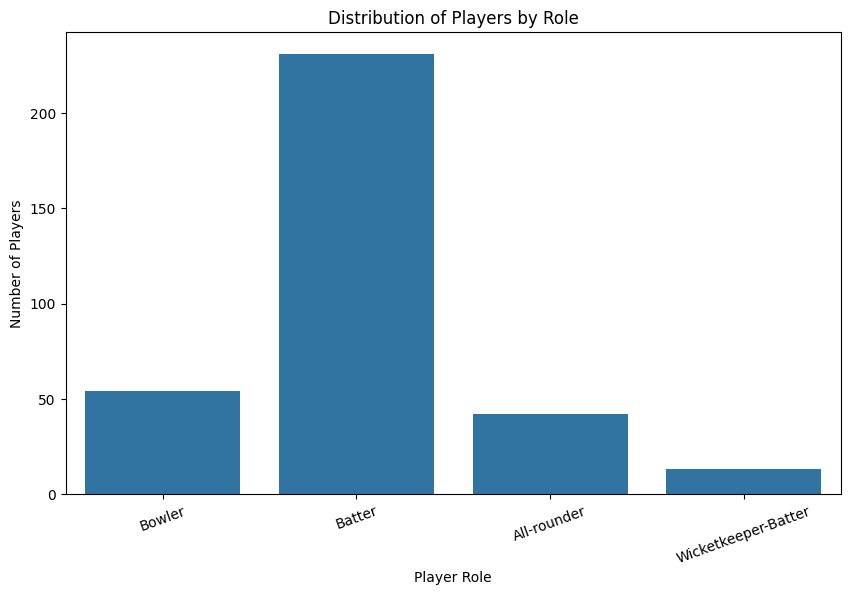

In [9]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="Player_Role"
)

plt.title("Distribution of Players by Role")
plt.xlabel("Player Role")
plt.ylabel("Number of Players")
plt.xticks(rotation=20)

plt.show()

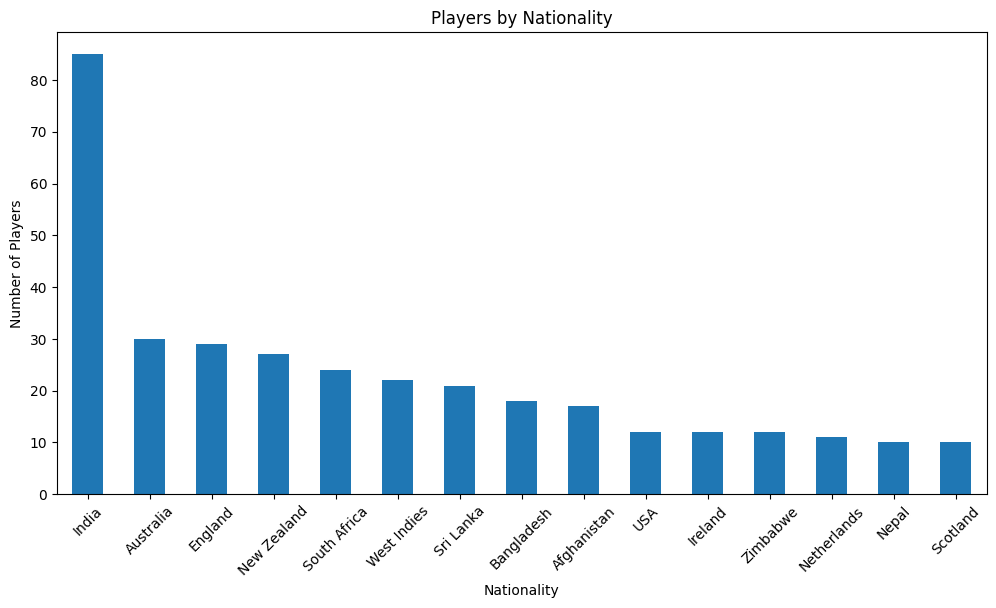

In [10]:
plt.figure(figsize=(12, 6))

df["Nationality"].value_counts().plot(kind="bar")

plt.title("Players by Nationality")
plt.xlabel("Nationality")
plt.ylabel("Number of Players")

plt.xticks(rotation=45)
plt.show()

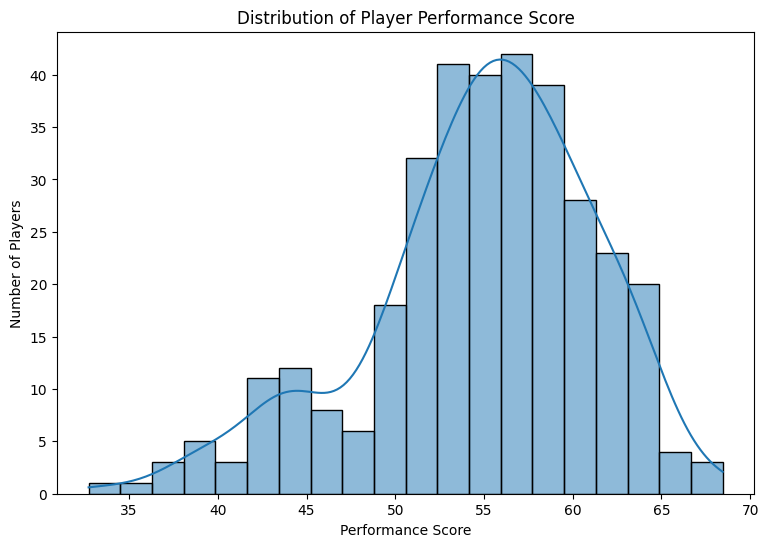

In [11]:
plt.figure(figsize=(9, 6))

sns.histplot(
    df["Performance_Score"],
    bins=20,
    kde=True
)

plt.title("Distribution of Player Performance Score")
plt.xlabel("Performance Score")
plt.ylabel("Number of Players")

plt.show()

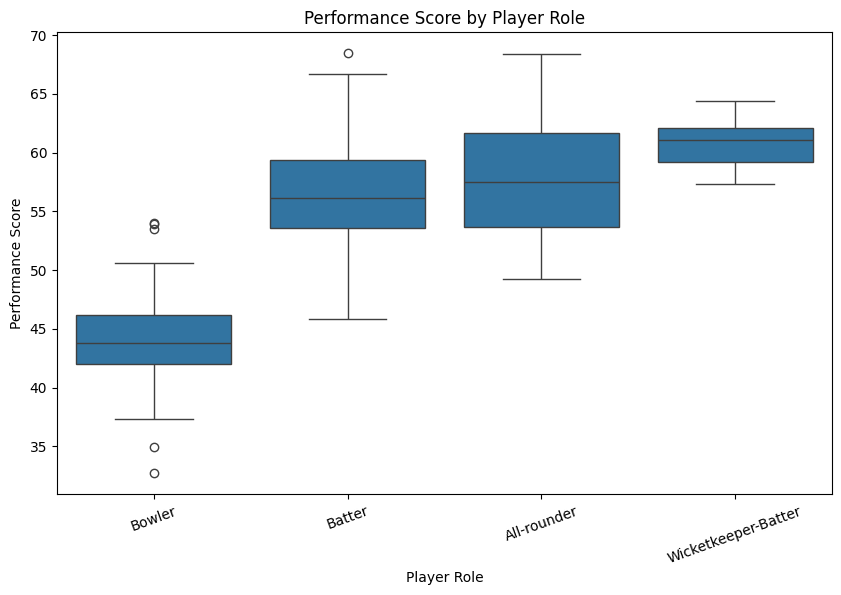

In [12]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Player_Role",
    y="Performance_Score"
)

plt.title("Performance Score by Player Role")
plt.xlabel("Player Role")
plt.ylabel("Performance Score")

plt.xticks(rotation=20)
plt.show()

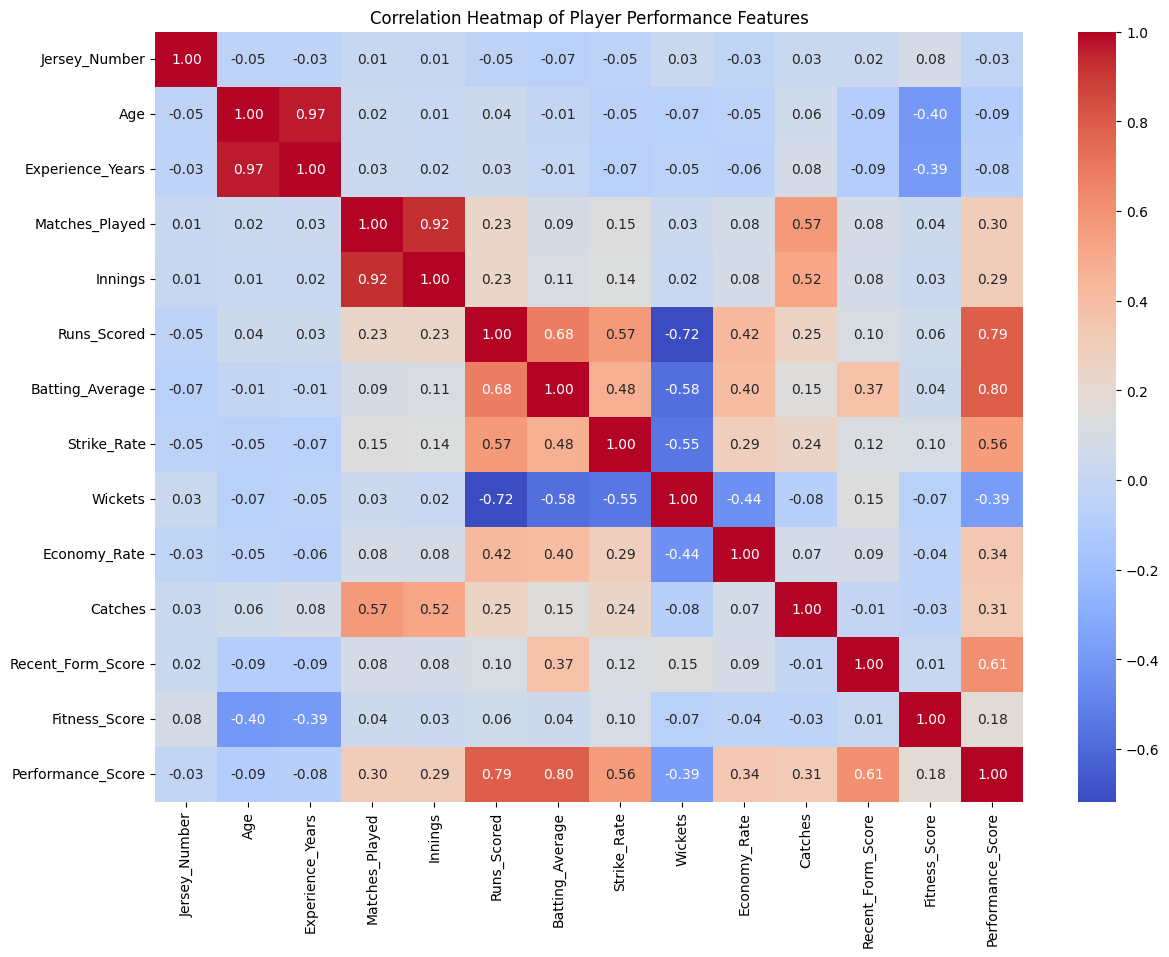

In [13]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(14, 10))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap of Player Performance Features")

plt.show()

In [14]:
X = df.drop("Performance_Score", axis=1)

y = df["Performance_Score"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (340, 19)
Target shape: (340,)


In [15]:
X = X.drop(
    ["Player_ID", "Player_Name", "Jersey_Number"],
    axis=1
)

print("Remaining features:")
print(X.columns.tolist())

Remaining features:
['Nationality', 'Player_Role', 'IPL_Franchise', 'Format', 'Age', 'Experience_Years', 'Matches_Played', 'Innings', 'Runs_Scored', 'Batting_Average', 'Strike_Rate', 'Wickets', 'Economy_Rate', 'Catches', 'Recent_Form_Score', 'Fitness_Score']


In [16]:
categorical_columns = X.select_dtypes(
    include=["object"]
).columns

numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns

print("Categorical columns:")
print(categorical_columns.tolist())

print("\nNumerical columns:")
print(numerical_columns.tolist())

Categorical columns:
['Nationality', 'Player_Role', 'IPL_Franchise', 'Format']

Numerical columns:
['Age', 'Experience_Years', 'Matches_Played', 'Innings', 'Runs_Scored', 'Batting_Average', 'Strike_Rate', 'Wickets', 'Economy_Rate', 'Catches', 'Recent_Form_Score', 'Fitness_Score']


In [17]:
X = pd.get_dummies(
    X,
    columns=categorical_columns,
    drop_first=True
)

print("Shape after encoding:", X.shape)

Shape after encoding: (340, 31)


In [21]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 272
Testing samples: 68


In [23]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


In [24]:
from sklearn.linear_model import Ridge

ridge_model = Ridge(alpha=1.0)

ridge_model.fit(
    X_train_scaled,
    y_train
)

ridge_predictions = ridge_model.predict(
    X_test_scaled
)

print("Ridge Regression completed!")

Ridge Regression completed!


In [25]:
from sklearn.linear_model import Lasso

lasso_model = Lasso(alpha=0.1)

lasso_model.fit(
    X_train_scaled,
    y_train
)

lasso_predictions = lasso_model.predict(
    X_test_scaled
)

print("Lasso Regression completed!")

Lasso Regression completed!


In [26]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# -------------------------
# RIDGE
# -------------------------

ridge_mae = mean_absolute_error(
    y_test,
    ridge_predictions
)

ridge_mse = mean_squared_error(
    y_test,
    ridge_predictions
)

ridge_rmse = np.sqrt(ridge_mse)

ridge_r2 = r2_score(
    y_test,
    ridge_predictions
)


# -------------------------
# LASSO
# -------------------------

lasso_mae = mean_absolute_error(
    y_test,
    lasso_predictions
)

lasso_mse = mean_squared_error(
    y_test,
    lasso_predictions
)

lasso_rmse = np.sqrt(lasso_mse)

lasso_r2 = r2_score(
    y_test,
    lasso_predictions
)


print("========== RIDGE REGRESSION ==========")
print("MAE  :", round(ridge_mae, 3))
print("MSE  :", round(ridge_mse, 3))
print("RMSE :", round(ridge_rmse, 3))
print("R²   :", round(ridge_r2, 3))


print("\n========== LASSO REGRESSION ==========")
print("MAE  :", round(lasso_mae, 3))
print("MSE  :", round(lasso_mse, 3))
print("RMSE :", round(lasso_rmse, 3))
print("R²   :", round(lasso_r2, 3))

========== RIDGE REGRESSION ==========
MAE  : 0.056
MSE  : 0.005
RMSE : 0.073
R²   : 1.0

========== LASSO REGRESSION ==========
MAE  : 0.27
MSE  : 0.13
RMSE : 0.36
R²   : 0.997


In [27]:
results = pd.DataFrame({
    "Model": [
        "Ridge Regression",
        "Lasso Regression"
    ],
    "MAE": [
        ridge_mae,
        lasso_mae
    ],
    "MSE": [
        ridge_mse,
        lasso_mse
    ],
    "RMSE": [
        ridge_rmse,
        lasso_rmse
    ],
    "R2 Score": [
        ridge_r2,
        lasso_r2
    ]
})

results.round(3)

,Model,MAE,MSE,RMSE,R2 Score
0,Ridge Regression,0.056,0.005,0.073,1.000
1,Lasso Regression,0.270,0.130,0.360,0.997


In [28]:
!pip install -q gradio

In [32]:

import gradio as gr
import pandas as pd
import numpy as np

# =====================================================
# PLAYER PERFORMANCE PREDICTION - COMPLETE GRADIO UI
# Requires: df, X_train, scaler, ridge_model, lasso_model
# =====================================================

# Check that the dataset and trained models exist
required_variables = [
    "df", "X_train", "scaler", "ridge_model", "lasso_model"
]

missing_variables = [
    name for name in required_variables if name not in globals()
]

if missing_variables:
    raise NameError(
        f"Missing variables: {missing_variables}. "
        "Run your dataset, preprocessing and model-training cells first."
    )

# Validate the dataset columns
required_columns = [
    "Player_Name", "Nationality", "Player_Role", "IPL_Franchise",
    "Format", "Age", "Experience_Years", "Matches_Played", "Innings",
    "Runs_Scored", "Batting_Average", "Strike_Rate", "Wickets",
    "Economy_Rate", "Catches", "Recent_Form_Score", "Fitness_Score"
]

missing_columns = [c for c in required_columns if c not in df.columns]

if missing_columns:
    raise ValueError(f"Dataset is missing columns: {missing_columns}")

player_names = sorted(df["Player_Name"].dropna().unique().tolist())

if not player_names:
    raise ValueError("No player names were found in the dataset.")

default_player_name = player_names[0]
default_player = df[df["Player_Name"] == default_player_name].iloc[0]

# =====================================================
# CSS DESIGN
# =====================================================

css = """
body {
    background: #080d18 !important;
}

.gradio-container {
    max-width: 100% !important;
    padding: 0 !important;
    margin: 0 auto !important;
    background: #080d18 !important;
    color: white !important;
}

/* Landing page */
.hero {
    min-height: 88vh;
    box-sizing: border-box;
    display: flex;
    flex-direction: column;
    align-items: center;
    justify-content: center;
    text-align: center;
    padding: 35px 20px;
    background:
        radial-gradient(ellipse at 50% 40%,
            #243b63 0%, #111d33 38%, #080d18 78%);
}

.hero-title {
    font-family: Arial, sans-serif;
    font-size: clamp(38px, 6.2vw, 88px);
    line-height: 1.08;
    font-weight: 900;
    letter-spacing: 2px;
    color: #ffffff;
    text-shadow: 0 5px 25px rgba(0,0,0,.45);
}

.hero-line {
    width: 85px;
    height: 4px;
    border-radius: 8px;
    background: #ef4444;
    margin: 28px 0;
}

.hero-subtitle {
    font-size: clamp(16px, 2vw, 23px);
    color: #cbd5e1;
    letter-spacing: 1px;
}

.start-button {
    display: block;
    width: min(260px, 85%);
    margin: 28px auto 0;
    height: 58px;
    border-radius: 9px !important;
    font-size: 17px !important;
    font-weight: 800 !important;
}

/* Prediction page */
.prediction-page {
    max-width: 1250px;
    margin: 0 auto;
    padding: 35px 25px;
}

.page-heading {
    color: white;
    font-size: 32px;
    font-weight: 800;
    margin-bottom: 6px;
}

.page-description {
    color: #9aabc4;
    margin-bottom: 24px;
}

.section-title {
    font-size: 21px;
    font-weight: 750;
    color: white;
    margin-bottom: 14px;
}

.input-section {
    background: #111a2b;
    border: 1px solid #293951;
    border-radius: 14px;
    padding: 22px;
}

label {
    color: #dbe5f3 !important;
}

input, textarea {
    color: white !important;
}

.predict-button {
    height: 56px;
    border-radius: 10px !important;
    font-size: 17px !important;
    font-weight: 800 !important;
}

.result-note {
    background: #111a2b;
    border: 1px solid #293951;
    border-radius: 12px;
    padding: 16px;
    color: #cbd5e1;
    line-height: 1.7;
}

.footer {
    text-align: center;
    color: #71829d;
    padding: 25px 10px;
}

@media (max-width: 700px) {
    .hero-title {
        letter-spacing: 0;
    }

    .prediction-page {
        padding: 20px 12px;
    }
}
"""

# =====================================================
# HELPER FUNCTIONS
# =====================================================

def safe_number(value):
    """Convert a dataset value to a number, using zero for missing values."""
    if pd.isna(value):
        return 0.0
    return float(value)


def load_player(player_name):
    """Load all available statistics for the selected dataset player."""
    matches = df[df["Player_Name"] == player_name]

    if matches.empty:
        raise ValueError("Player not found in the dataset.")

    p = matches.iloc[0]

    return (
        p["Nationality"],
        p["Player_Role"],
        p["IPL_Franchise"],
        p["Format"],
        safe_number(p["Age"]),
        safe_number(p["Experience_Years"]),
        safe_number(p["Matches_Played"]),
        safe_number(p["Innings"]),
        safe_number(p["Runs_Scored"]),
        safe_number(p["Batting_Average"]),
        safe_number(p["Strike_Rate"]),
        safe_number(p["Wickets"]),
        safe_number(p["Economy_Rate"]),
        safe_number(p["Catches"]),
        safe_number(p["Recent_Form_Score"]),
        safe_number(p["Fitness_Score"])
    )


def predict_ui(
    Nationality,
    Player_Role,
    IPL_Franchise,
    Format,
    Age,
    Experience_Years,
    Matches_Played,
    Innings,
    Runs_Scored,
    Batting_Average,
    Strike_Rate,
    Wickets,
    Economy_Rate,
    Catches,
    Recent_Form_Score,
    Fitness_Score
):
    # Build the input using the same feature names as training.
    input_data = pd.DataFrame([{
        "Nationality": Nationality,
        "Player_Role": Player_Role,
        "IPL_Franchise": IPL_Franchise,
        "Format": Format,
        "Age": safe_number(Age),
        "Experience_Years": safe_number(Experience_Years),
        "Matches_Played": safe_number(Matches_Played),
        "Innings": safe_number(Innings),
        "Runs_Scored": safe_number(Runs_Scored),
        "Batting_Average": safe_number(Batting_Average),
        "Strike_Rate": safe_number(Strike_Rate),
        "Wickets": safe_number(Wickets),
        "Economy_Rate": safe_number(Economy_Rate),
        "Catches": safe_number(Catches),
        "Recent_Form_Score": safe_number(Recent_Form_Score),
        "Fitness_Score": safe_number(Fitness_Score)
    }])

    # Use the same one-hot encoding convention as model training.
    categorical = [
        "Nationality", "Player_Role", "IPL_Franchise", "Format"
    ]

    input_encoded = pd.get_dummies(
        input_data,
        columns=categorical,
        drop_first=True
    )

    # Ensure identical feature names, order and count.
    input_encoded = input_encoded.reindex(
        columns=X_train.columns,
        fill_value=0
    )

    # Apply the scaler fitted on the training dataset.
    input_scaled = scaler.transform(input_encoded)

    ridge_score = float(ridge_model.predict(input_scaled)[0])
    lasso_score = float(lasso_model.predict(input_scaled)[0])
    average_score = (ridge_score + lasso_score) / 2

    # These are scores, not percentages or accuracy measurements.
    return (
        round(average_score, 2),
        round(ridge_score, 2),
        round(lasso_score, 2)
    )


def start_prediction():
    return gr.update(visible=False), gr.update(visible=True)


def go_home():
    return gr.update(visible=True), gr.update(visible=False)


# =====================================================
# BUILD THE APP
# =====================================================

with gr.Blocks(title="Player Performance Prediction", css=css) as demo:

    # ---------------- LANDING PAGE ----------------

    with gr.Column(visible=True, elem_id="landing") as landing_page:

        gr.HTML("""
        <div class="hero">
            <div class="hero-title">
                PLAYER PERFORMANCE<br>PREDICTION
            </div>
            <div class="hero-line"></div>
            <div class="hero-subtitle">
                Powered by Ridge &amp; Lasso Regression
            </div>
        </div>
        """)

        start_button = gr.Button(
            "GET STARTED  →",
            variant="primary",
            elem_classes=["start-button"]
        )

    # ---------------- PREDICTION PAGE ----------------

    with gr.Column(
        visible=False,
        elem_classes=["prediction-page"]
    ) as prediction_page:

        gr.HTML("""
        <div class="page-heading">Player Performance Prediction</div>
        <div class="page-description">
            Select a player from the dataset or enter custom statistics,
            then compare the two model predictions.
        </div>
        """)

        with gr.Column(elem_classes=["input-section"]):
            gr.HTML('<div class="section-title">Select Player</div>')

            player_name = gr.Dropdown(
                choices=player_names,
                value=default_player_name,
                label="Player Name",
                allow_custom_value=False
            )

            load_button = gr.Button(
                "LOAD PLAYER DETAILS",
                variant="secondary"
            )

        with gr.Row():

            with gr.Column(elem_classes=["input-section"]):
                gr.HTML('<div class="section-title">Player Information</div>')

                Nationality = gr.Dropdown(
                    choices=sorted(df["Nationality"].dropna().unique().tolist()),
                    value=default_player["Nationality"],
                    label="Nationality"
                )

                Player_Role = gr.Dropdown(
                    choices=sorted(df["Player_Role"].dropna().unique().tolist()),
                    value=default_player["Player_Role"],
                    label="Player Role"
                )

                IPL_Franchise = gr.Dropdown(
                    choices=sorted(df["IPL_Franchise"].dropna().unique().tolist()),
                    value=default_player["IPL_Franchise"],
                    label="IPL Franchise"
                )

                Format = gr.Dropdown(
                    choices=sorted(df["Format"].dropna().unique().tolist()),
                    value=default_player["Format"],
                    label="Format"
                )

                Age = gr.Number(label="Age", value=safe_number(default_player["Age"]))
                Experience_Years = gr.Number(
                    label="Experience Years",
                    value=safe_number(default_player["Experience_Years"])
                )

            with gr.Column(elem_classes=["input-section"]):
                gr.HTML('<div class="section-title">Performance Statistics</div>')

                Matches_Played = gr.Number(
                    label="Matches Played",
                    value=safe_number(default_player["Matches_Played"])
                )

                Innings = gr.Number(
                    label="Innings",
                    value=safe_number(default_player["Innings"])
                )

                Runs_Scored = gr.Number(
                    label="Runs Scored",
                    value=safe_number(default_player["Runs_Scored"])
                )

                Batting_Average = gr.Number(
                    label="Batting Average",
                    value=safe_number(default_player["Batting_Average"])
                )

                Strike_Rate = gr.Number(
                    label="Strike Rate",
                    value=safe_number(default_player["Strike_Rate"])
                )

                Wickets = gr.Number(
                    label="Wickets",
                    value=safe_number(default_player["Wickets"])
                )

                Economy_Rate = gr.Number(
                    label="Economy Rate",
                    value=safe_number(default_player["Economy_Rate"])
                )

                Catches = gr.Number(
                    label="Catches",
                    value=safe_number(default_player["Catches"])
                )

                Recent_Form_Score = gr.Number(
                    label="Recent Form Score",
                    value=safe_number(default_player["Recent_Form_Score"])
                )

                Fitness_Score = gr.Number(
                    label="Fitness Score",
                    value=safe_number(default_player["Fitness_Score"])
                )

        predict_button = gr.Button(
            "PREDICT PERFORMANCE",
            variant="primary",
            elem_classes=["predict-button"]
        )

        gr.HTML('<div class="section-title">Prediction Results</div>')

        with gr.Row():
            overall = gr.Number(
                label="Overall Predicted Score",
                precision=2,
                interactive=False
            )

            ridge_output = gr.Number(
                label="Ridge Regression Score",
                precision=2,
                interactive=False
            )

            lasso_output = gr.Number(
                label="Lasso Regression Score",
                precision=2,
                interactive=False
            )

        gr.Markdown("""
        <div class="result-note">

        **Understanding the results**

        - **Overall Predicted Score:** Average of the Ridge and Lasso predictions.
        - **Ridge Regression:** Prediction using L2 regularization.
        - **Lasso Regression:** Prediction using L1 regularization.

        These numbers are predicted `Performance_Score` values, not accuracy
        percentages. Their interpretation depends on how the target score
        was defined in the dataset.

        </div>
        """)

        back_button = gr.Button("← BACK TO HOME", variant="secondary")

        gr.HTML("""
        <div class="footer">
            Player Performance Prediction · Ridge Regression · Lasso Regression
        </div>
        """)

    # ---------------- BUTTON EVENTS ----------------

    start_button.click(
        fn=start_prediction,
        inputs=[],
        outputs=[landing_page, prediction_page]
    )

    back_button.click(
        fn=go_home,
        inputs=[],
        outputs=[landing_page, prediction_page]
    )

    player_outputs = [
        Nationality,
        Player_Role,
        IPL_Franchise,
        Format,
        Age,
        Experience_Years,
        Matches_Played,
        Innings,
        Runs_Scored,
        Batting_Average,
        Strike_Rate,
        Wickets,
        Economy_Rate,
        Catches,
        Recent_Form_Score,
        Fitness_Score
    ]

    load_button.click(
        fn=load_player,
        inputs=[player_name],
        outputs=player_outputs
    )

    predict_button.click(
        fn=predict_ui,
        inputs=player_outputs,
        outputs=[overall, ridge_output, lasso_output]
    )

# Launch only once, at the end.
demo.launch(share=True)


/tmp/ipykernel_556/4137643694.py:308: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: css. Please pass these parameters to launch() instead.
  with gr.Blocks(title="Player Performance Prediction", css=css) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://bbfa71e1898801e8bd.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
